# 01. API Key로 사용 가능한 모델 목록 조회

실행: VS Code 우측 상단에서 커널을 `.venv`로 선택한 뒤 셀을 위에서부터 차례로 실행

In [ ]:
import anthropic    # anthropic = Anthropic의 공식 파이썬 SDK. HTTP 요청을 직접 작성하지 않고 함수 호출만으로 API 사용을 도와줌
from dotenv import load_dotenv

# .env의 ANTHROPIC_API_KEY를 환경변수로 로드 → Anthropic()이 자동으로 읽음
# ANTHROPIC_API_KEY가 아니라 다른 이름으로 키를 저장하면 자동으로 읽지 못함
load_dotenv()

client = anthropic.Anthropic()

In [ ]:
def show_list() -> None:
    # 요청 과다, 서버 오류, 네트워크 끊김 등으로 오류가 발생하는 경우 SDK가 2번까지 자동으로 재시도
    # try 문은 재시도를 해도 안 되는 경우에 대한 예외처리
    try:
        # list()는 페이지네이션을 자동으로 처리하므로 그대로 순회하면 전체 목록을 얻는다
        models = list(client.models.list())
    except anthropic.AuthenticationError:
        print("인증 실패: .env의 ANTHROPIC_API_KEY를 확인하세요.")
        return
    except anthropic.APIConnectionError:
        print("네트워크 오류: 인터넷 연결을 확인하세요.")
        return

    print(f"사용 가능한 모델: {len(models)}개\n")
    print(f"{'Model ID':<28} {'Display name':<24} {'Context':>10} {'Max out':>9}  Created") # 표 형태로 보여주기
    print("-" * 88)
    for m in models:
        context = f"{m.max_input_tokens:,}" if m.max_input_tokens else "-"
        max_out = f"{m.max_tokens:,}" if m.max_tokens else "-"
        print(
            f"{m.id:<28} {m.display_name:<24} {context:>10} {max_out:>9}  "
            f"{m.created_at:%Y-%m-%d}"
        )

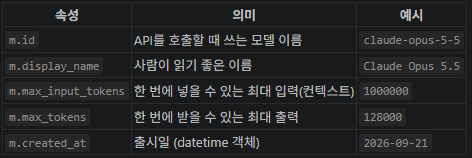

In [3]:
show_list()

사용 가능한 모델: 13개

Model ID                     Display name                Context   Max out  Created
----------------------------------------------------------------------------------------
claude-haiku-5-5             Claude Haiku 5.5          1,000,000   128,000  2026-10-07
claude-sonnet-5-5            Claude Sonnet 5.5         1,000,000   128,000  2026-09-28
claude-opus-5-5              Claude Opus 5.5           1,000,000   128,000  2026-09-21
claude-fable-5-1             Claude Fable 5.1          1,000,000   128,000  2026-08-28
claude-opus-5                Claude Opus 5             1,000,000   128,000  2026-07-24
claude-sonnet-5              Claude Sonnet 5           1,000,000   128,000  2026-06-29
claude-fable-5               Claude Fable 5            1,000,000   128,000  2026-06-07
claude-opus-4-8              Claude Opus 4.8           1,000,000   128,000  2026-05-28
claude-opus-4-7              Claude Opus 4.7           1,000,000   128,000  2026-04-14
claude-sonnet-4-6           